# Image Correction

**Experiment with the following tasks for image correction:**

- Histogram computation (visualize histogram for each color model used)
- Histogram equalization - for multiple color models (Grayscale, RGB, YCbCr, HSV, XYZ, Lab). Make assumption how to properly correct the image using following color models and document the steps with your reasoning.
- Gamma correction (hint: pow)
- *Optional*: Source -> Target color correction using eCDF (effective Cummulative Distribution Function) and linear interpolation
    - Target is an image you selected from the dataset. We want to change the color distribution of other (sources) images to the target one
    - for RGB and YCbCr only


In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

## Histogram computation and visualization

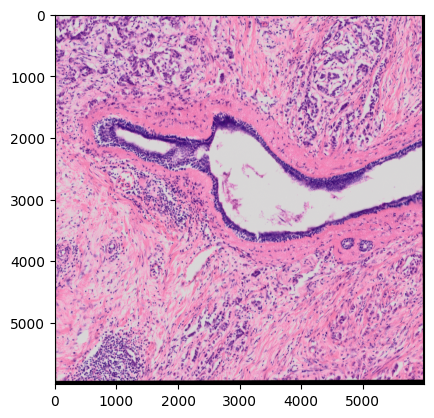

In [2]:
file1 = 'images/HMRegistred.png'
file2 = 'images/P63Registred.png'

file = file1

# Load the image
img = cv.imread(file)

# Convert to 32-bit float format
float32_img = img.astype(np.float32) / 255.0

# show the image
plt.imshow(img[:, :, ::-1])
plt.show()

### Grayscale

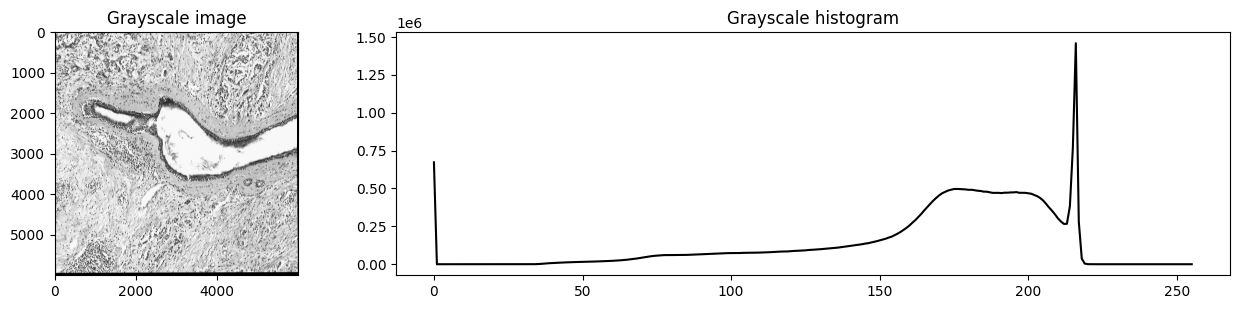

In [3]:
# Convert the image to grayscale
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Calculate histogram in grayscale
gray_hist = cv.calcHist([gray_img], [0], None, [256], [0, 256])

# Plot grayscale image and histogram
plt.figure(figsize=(15, 10))
ax1 = plt.subplot2grid(shape=(7, 7), loc=(0, 0), colspan=2, rowspan=2)
ax2 = plt.subplot2grid(shape=(7, 7), loc=(0, 2), colspan=4, rowspan=2)
ax1.set_title('Grayscale image')
ax1.imshow(gray_img, cmap='gray')
ax2.set_title('Grayscale histogram')
ax2.plot(gray_hist, color='black')
plt.tight_layout()
plt.show()

### RGB color space

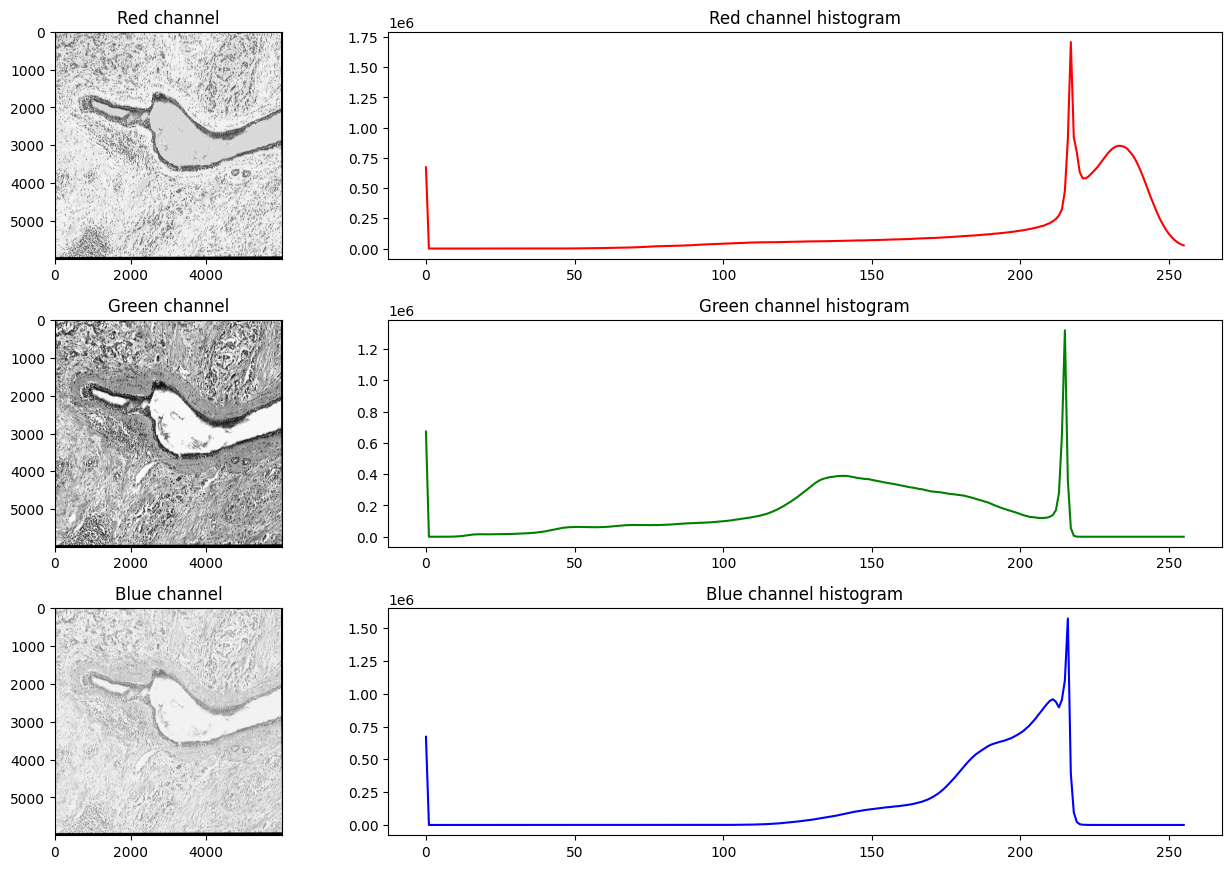

In [4]:
# Split the image into R, G, and B channels
B, G, R = cv.split(img)

# Calculate histogram in RGB color space
hist_r = cv.calcHist([R], [0], None, [256], [0, 256])
hist_g = cv.calcHist([G], [0], None, [256], [0, 256])
hist_b = cv.calcHist([B], [0], None, [256], [0, 256])

# Plot channels and histograms
plt.figure(figsize=(15, 10))
ax1 = plt.subplot2grid(shape=(7, 7), loc=(0, 0), colspan=2, rowspan=2)
ax2 = plt.subplot2grid(shape=(7, 7), loc=(0, 2), colspan=4, rowspan=2)
ax3 = plt.subplot2grid(shape=(7, 7), loc=(2, 0), colspan=2, rowspan=2)
ax4 = plt.subplot2grid(shape=(7, 7), loc=(2, 2), colspan=4, rowspan=2)
ax5 = plt.subplot2grid(shape=(7, 7), loc=(4, 0), colspan=2, rowspan=2)
ax6 = plt.subplot2grid(shape=(7, 7), loc=(4, 2), colspan=4, rowspan=2)
ax1.set_title('Red channel')
ax1.imshow(R, cmap='gray')
ax2.set_title('Red channel histogram')
ax2.plot(hist_r, color='red')
ax3.set_title('Green channel')
ax3.imshow(G, cmap='gray')
ax4.set_title('Green channel histogram')
ax4.plot(hist_g, color='green')
ax5.set_title('Blue channel')
ax5.imshow(B, cmap='gray')
ax6.set_title('Blue channel histogram')
ax6.plot(hist_b, color='blue')
plt.tight_layout()
plt.show()

### CIE XYZ color space

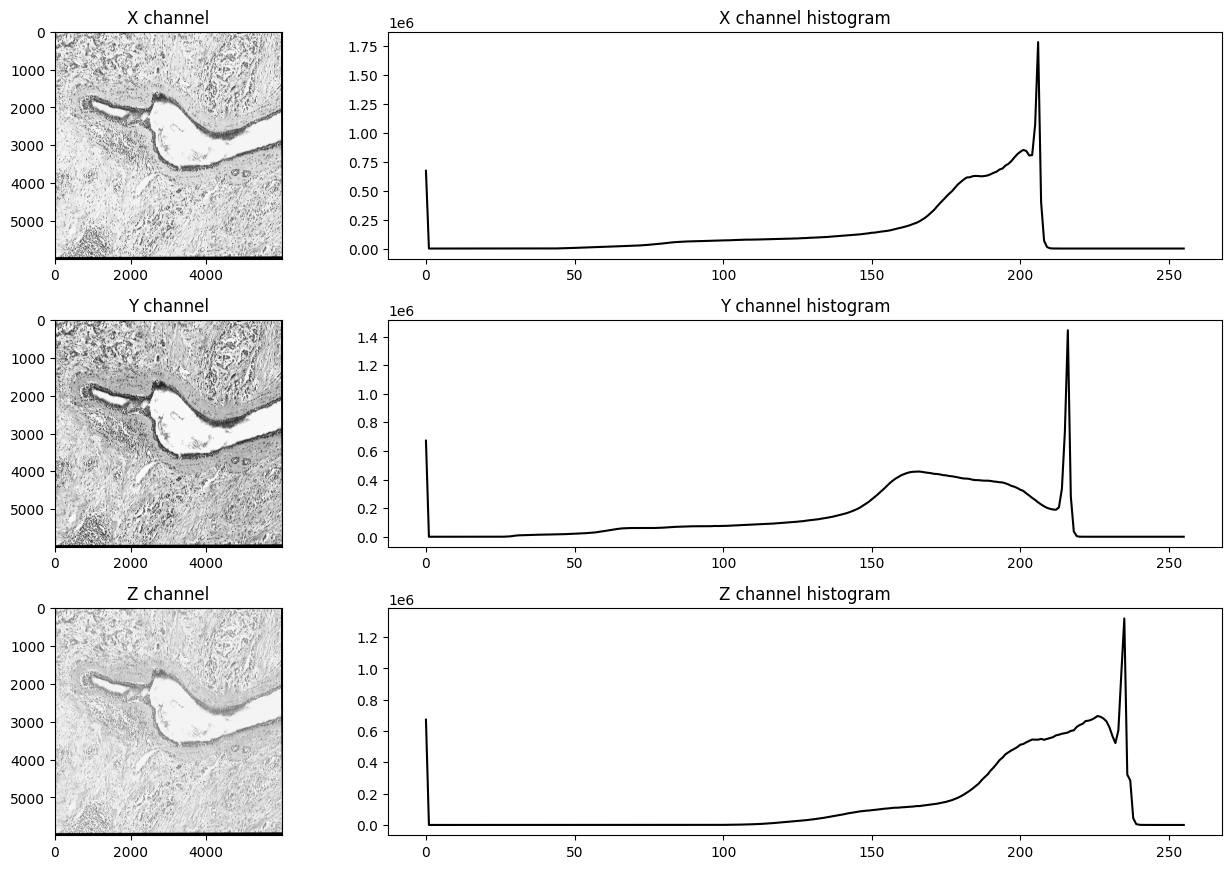

In [5]:
# Convert the image to CIE XYZ color space
xyz_img = cv.cvtColor(float32_img, cv.COLOR_BGR2XYZ)

# Split the image into X, Y, and Z channels
X, Y, Z = cv.split(xyz_img)

# Calculate histogram in XYZ color space
hist_x = cv.calcHist([X], [0], None, [256], [0, 1])
hist_y = cv.calcHist([Y], [0], None, [256], [0, 1])
hist_z = cv.calcHist([Z], [0], None, [256], [0, 1])

# Plot channels and histograms
plt.figure(figsize=(15, 10))
ax1 = plt.subplot2grid(shape=(7, 7), loc=(0, 0), colspan=2, rowspan=2)
ax2 = plt.subplot2grid(shape=(7, 7), loc=(0, 2), colspan=4, rowspan=2)
ax3 = plt.subplot2grid(shape=(7, 7), loc=(2, 0), colspan=2, rowspan=2)
ax4 = plt.subplot2grid(shape=(7, 7), loc=(2, 2), colspan=4, rowspan=2)
ax5 = plt.subplot2grid(shape=(7, 7), loc=(4, 0), colspan=2, rowspan=2)
ax6 = plt.subplot2grid(shape=(7, 7), loc=(4, 2), colspan=4, rowspan=2)
ax1.set_title('X channel')
ax1.imshow(X, cmap='gray')
ax2.set_title('X channel histogram')
ax2.plot(hist_x, color='black')
ax3.set_title('Y channel')
ax3.imshow(Y, cmap='gray')
ax4.set_title('Y channel histogram')
ax4.plot(hist_y, color='black')
ax5.set_title('Z channel')
ax5.imshow(Z, cmap='gray')
ax6.set_title('Z channel histogram')
ax6.plot(hist_z, color='black')
plt.tight_layout()
plt.show()

#### CIE Lab color space

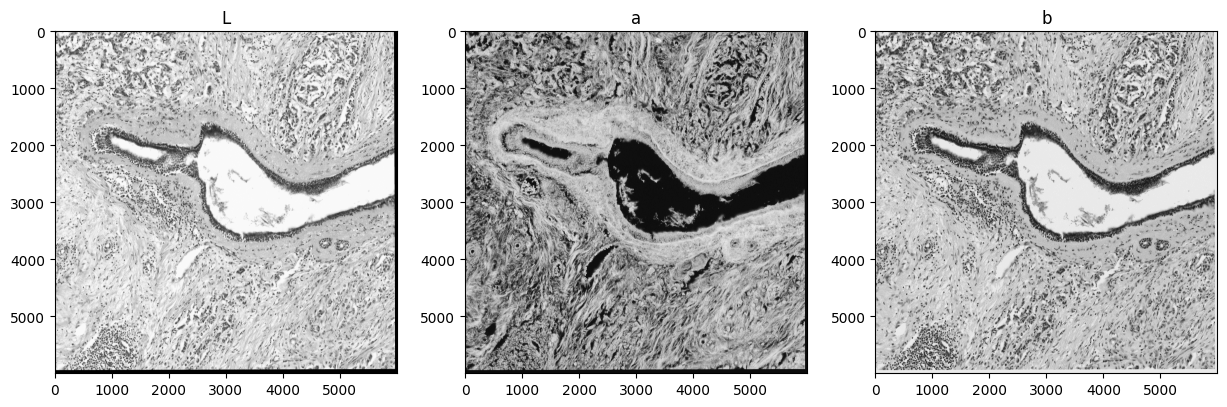

In [6]:
# Convert the image to CIE LAB color space
lab_img = cv.cvtColor(float32_img, cv.COLOR_BGR2LAB)

# Split the image into L, A, and B channels
L, A, B = cv.split(lab_img)

# Plot the channels
plt.figure(figsize=(15, 15))
plt.subplot(131)
plt.title('L')
plt.imshow(L, cmap='gray')
plt.subplot(132)
plt.title('a')
plt.imshow(A, cmap='gray')
plt.subplot(133)
plt.title('b')
plt.imshow(B, cmap='gray')
plt.show()

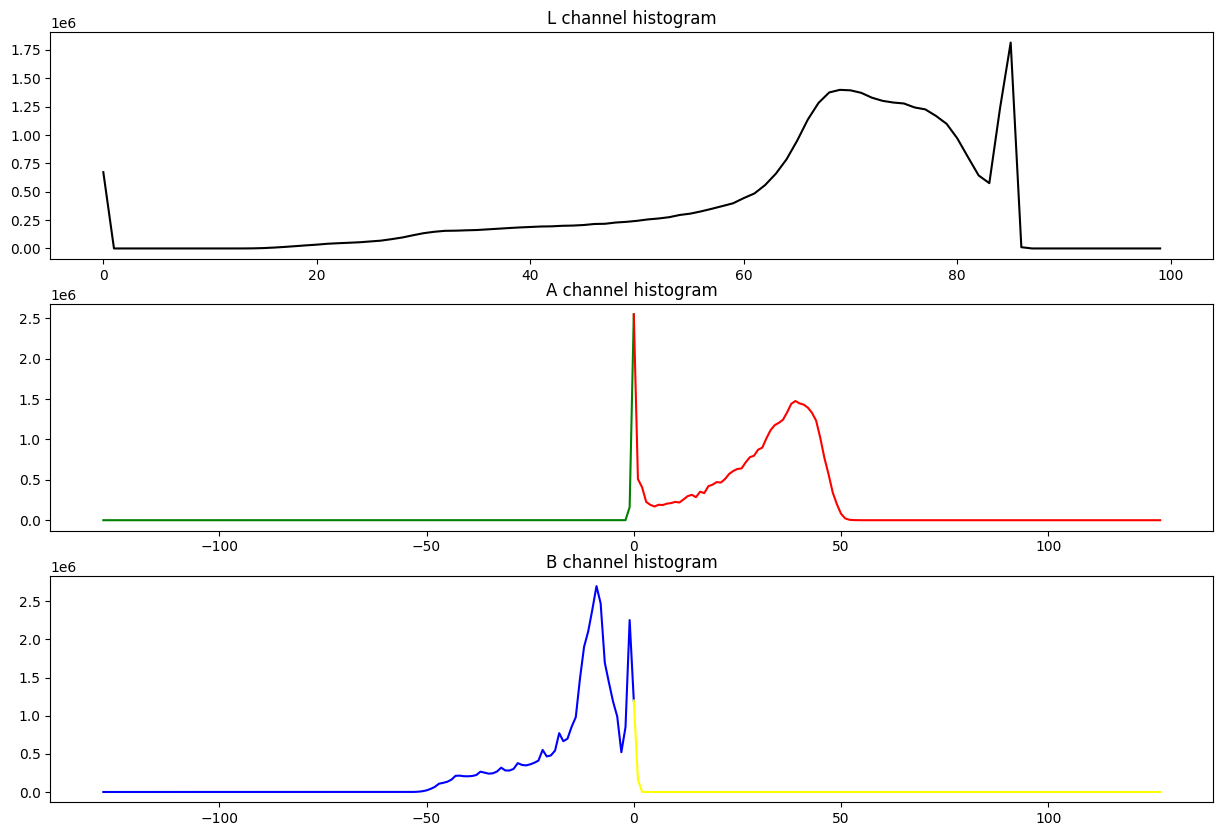

In [7]:
# Calculate histogram in LAB color space
hist_l = cv.calcHist([L], [0], None, [100], [0, 101])
hist_a = cv.calcHist([A], [0], None, [256], [-128, 128])
hist_b = cv.calcHist([B], [0], None, [256], [-128, 128])

# convert histogram to -128..128 range
hist_a = np.reshape(hist_a, (256,)) - 128
hist_b = np.reshape(hist_b, (256,)) - 128

negative_part = np.arange(-128, 1)
positive_part = np.arange(0, 128)

# Plot the histograms
plt.figure(figsize=(15, 10))
plt.subplot(311)
plt.title('L channel histogram')
plt.plot(hist_l, color='black')
plt.subplot(312)
plt.title('A channel histogram')
plt.plot(negative_part, hist_a[:129], color='green')
plt.plot(positive_part, hist_a[128:], color='red')
plt.subplot(313)
plt.title('B channel histogram')
plt.plot(negative_part, hist_b[:129], color='blue')
plt.plot(positive_part, hist_b[128:], color='yellow')
plt.show()

### HSV color space

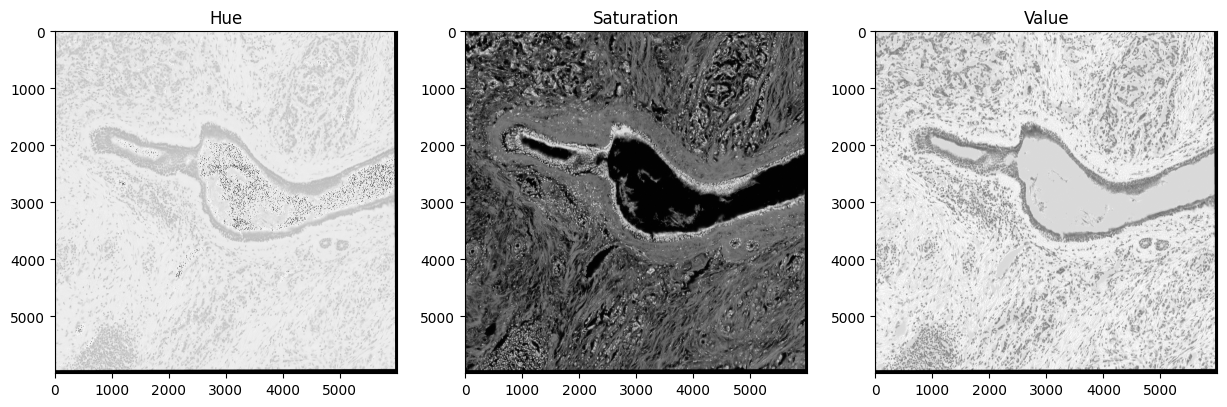

In [8]:
# Convert the image to HSV color space
hsv_img = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Split the image into H, S, and V channels
H, S, V = cv.split(hsv_img)

# Plot the channels
plt.figure(figsize=(15, 15))
plt.subplot(131)
plt.title('Hue')
plt.imshow(H, cmap='gray')
plt.subplot(132)
plt.title('Saturation')
plt.imshow(S, cmap='gray')
plt.subplot(133)
plt.title('Value')
plt.imshow(V, cmap='gray')
plt.show()

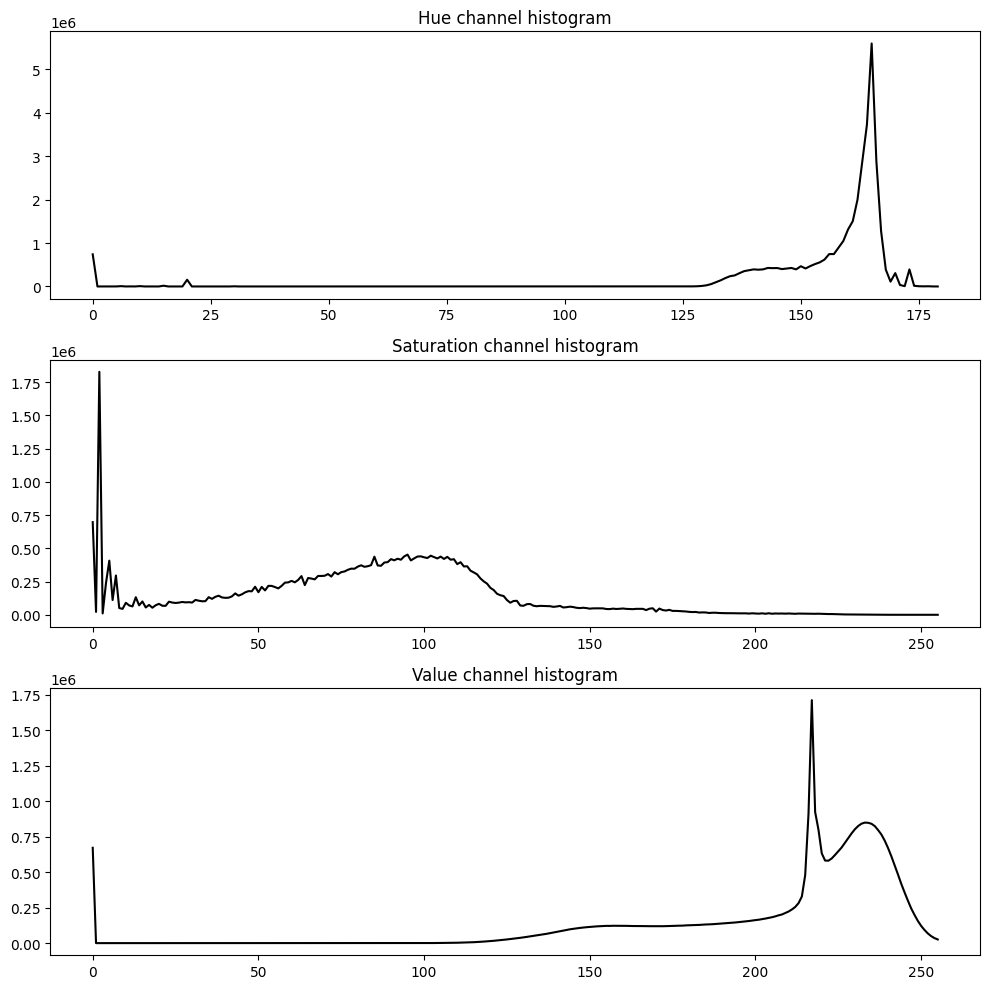

In [9]:
# Calculate histogram in HSV color space
hist_hue = cv.calcHist([H], [0], None, [180], [0, 180])
hist_sat = cv.calcHist([S], [0], None, [256], [0, 256])
hist_val = cv.calcHist([V], [0], None, [256], [0, 256])

# Plot the histograms
plt.figure(figsize=(10, 10))
plt.subplot(311)
plt.title('Hue channel histogram')
plt.plot(hist_hue, color='black')
plt.subplot(312)
plt.title('Saturation channel histogram')
plt.plot(hist_sat, color='black')
plt.subplot(313)
plt.title('Value channel histogram')
plt.plot(hist_val, color='black')
plt.tight_layout()
plt.show()

### HLS color space

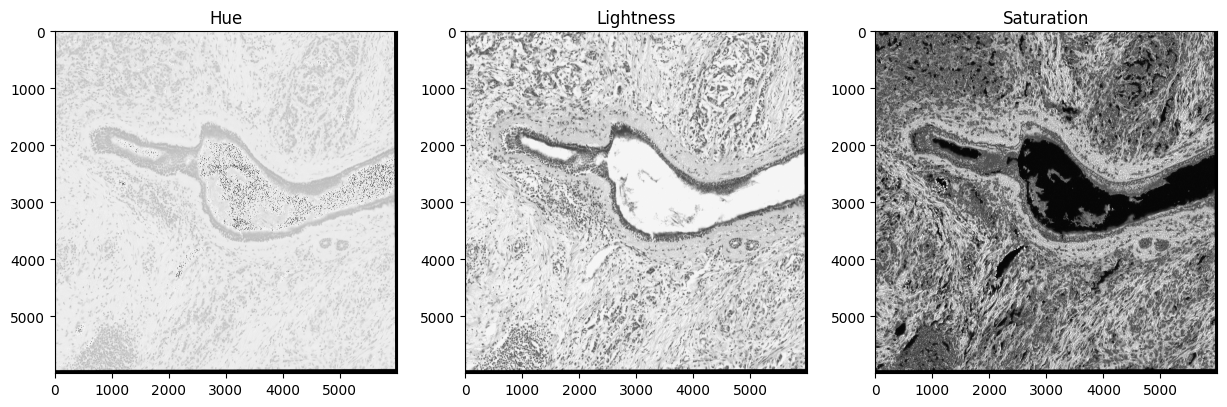

In [10]:
# Convert the image to HLS color space
hls_img = cv.cvtColor(img, cv.COLOR_BGR2HLS)

# Split the image into H, L, and S channels
H, L, S = cv.split(hls_img)

# Plot the channels
plt.figure(figsize=(15, 15))
plt.subplot(131)
plt.title('Hue')
plt.imshow(H, cmap='gray')
plt.subplot(132)
plt.title('Lightness')
plt.imshow(L, cmap='gray')
plt.subplot(133)
plt.title('Saturation')
plt.imshow(S, cmap='gray')
plt.show()

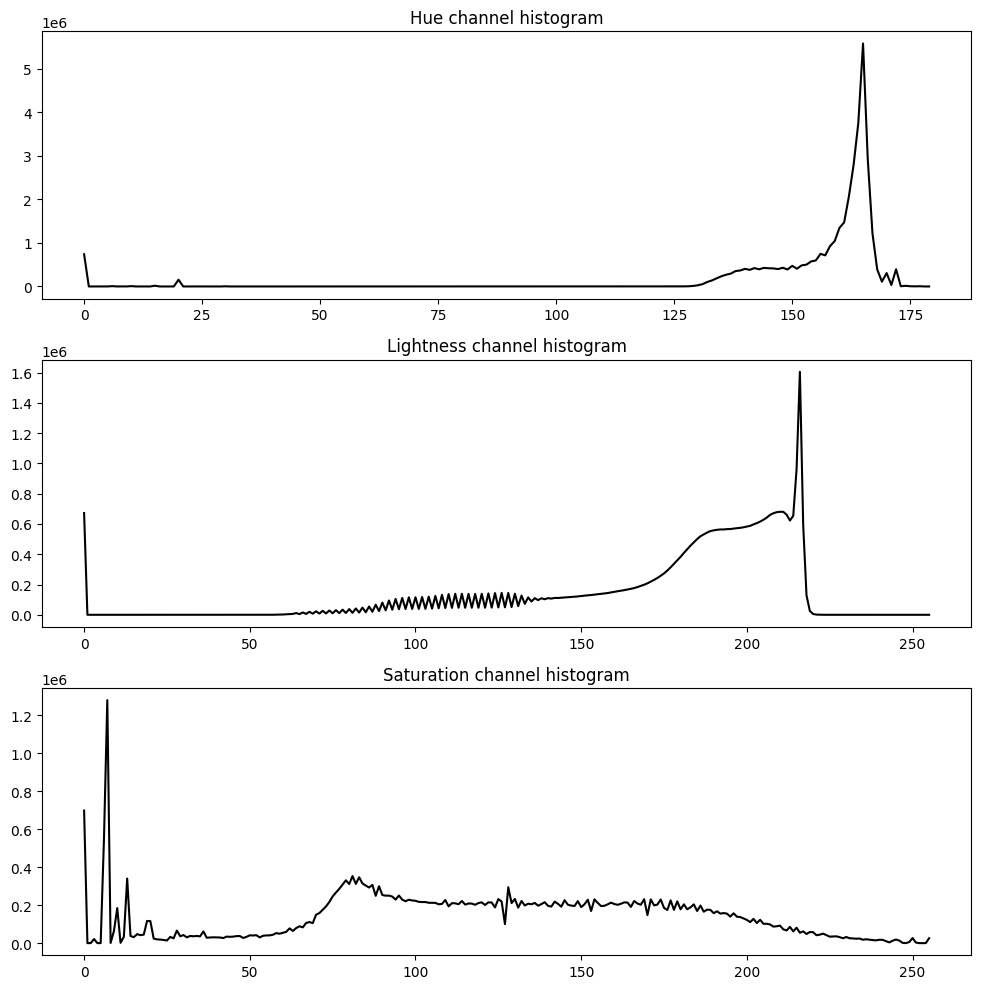

In [11]:
# Calculate histogram in HLS color space
hist_hue = cv.calcHist([H], [0], None, [180], [0, 180])
hist_light = cv.calcHist([L], [0], None, [256], [0, 256])
hist_sat = cv.calcHist([S], [0], None, [256], [0, 256])

# Plot the histograms
plt.figure(figsize=(10, 10))
plt.subplot(311)
plt.title('Hue channel histogram')
plt.plot(hist_hue, color='black')
plt.subplot(312)
plt.title('Lightness channel histogram')
plt.plot(hist_light, color='black')
plt.subplot(313)
plt.title('Saturation channel histogram')
plt.plot(hist_sat, color='black')
plt.tight_layout()
plt.show()

### YCbCr color space

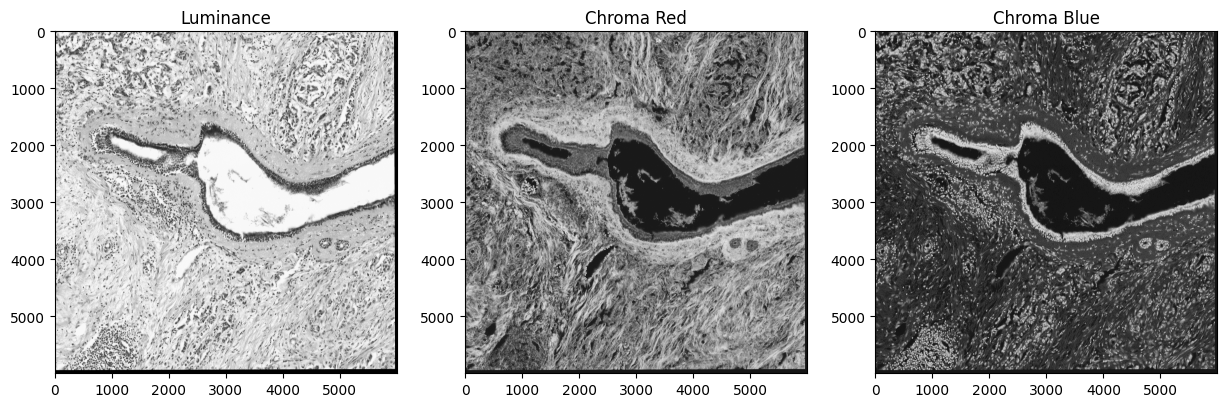

In [12]:
# Convert the image to YCbCr color space
ycrcb_img = cv.cvtColor(img, cv.COLOR_BGR2YCrCb)

# Split the image into Y, Cb, and Cr channels
Y, Cr, Cb = cv.split(ycrcb_img)

# Plot the channels
plt.figure(figsize=(15, 15))
plt.subplot(131)
plt.title('Luminance')
plt.imshow(Y, cmap='gray')
plt.subplot(132)
plt.title('Chroma Red')
plt.imshow(Cr, cmap='gray')
plt.subplot(133)
plt.title('Chroma Blue')
plt.imshow(Cb, cmap='gray')
plt.show()

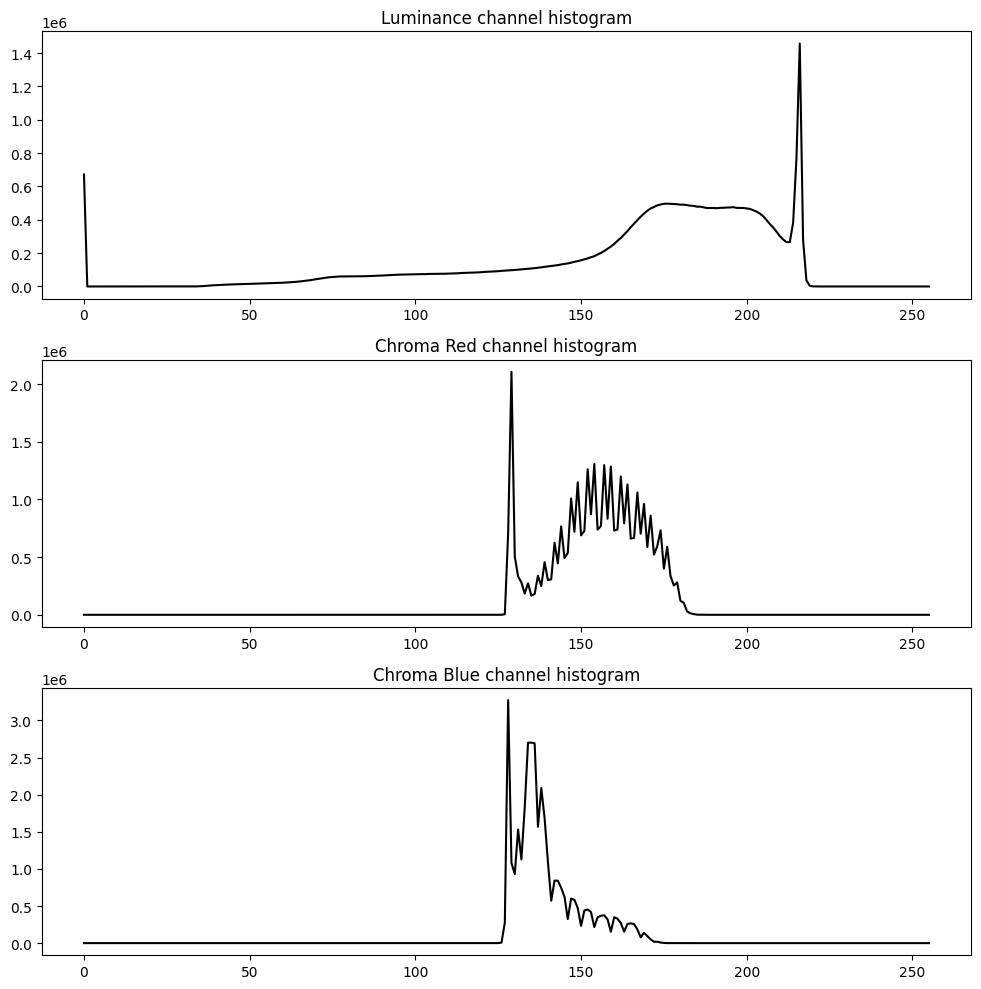

In [13]:
# Calculate histogram in YCbCr color space
hist_y = cv.calcHist([Y], [0], None, [256], [0, 256])
hist_cr = cv.calcHist([Cr], [0], None, [256], [0, 256])
hist_cb = cv.calcHist([Cb], [0], None, [256], [0, 256])

# Plot the histograms
plt.figure(figsize=(10, 10))
plt.subplot(311)
plt.title('Luminance channel histogram')
plt.plot(hist_y, color='black')
plt.subplot(312)
plt.title('Chroma Red channel histogram')
plt.plot(hist_cr, color='black')
plt.subplot(313)
plt.title('Chroma Blue channel histogram')
plt.plot(hist_cb, color='black')
plt.tight_layout()
plt.show()

## Histogram equalization

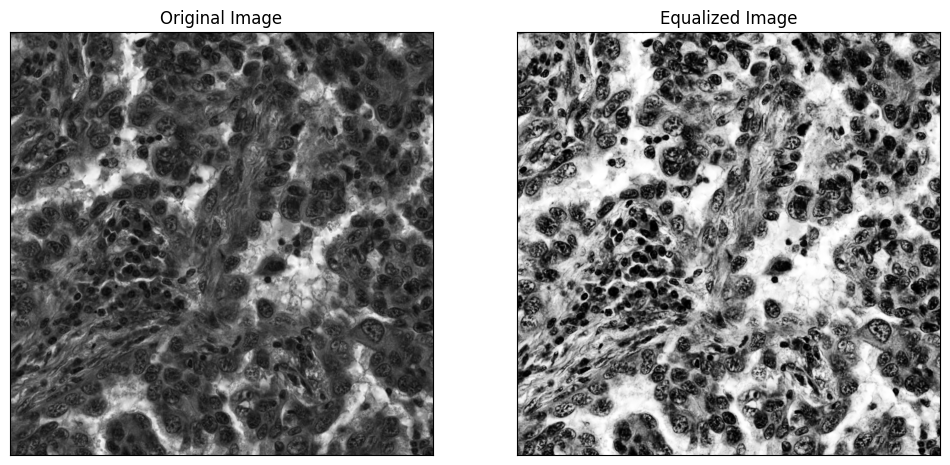

In [14]:
file = 'images/Histology nuclei/TCGA-49-4488-01Z-00-DX1.tif'

# Load image
img = cv.imread(file)

# Convert the image to grayscale
gray_img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Apply histogram equalization
equ = cv.equalizeHist(gray_img)

# plot images
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(gray_img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(equ, cmap='gray')
plt.title('Equalized Image'), plt.xticks([]), plt.yticks([])
plt.show()

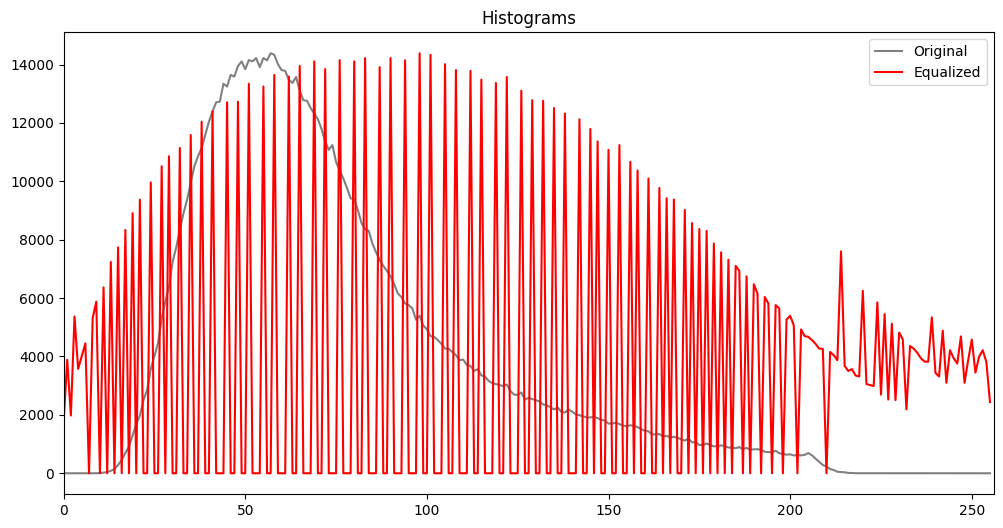

In [15]:
gray_hist = cv.calcHist([gray_img], [0], None, [256], [0, 256])
equ_hist = cv.calcHist([equ], [0], None, [256], [0, 256])

# plot histograms
plt.figure(figsize=(12, 6))
plt.title('Histograms')
plt.plot(gray_hist, color='gray')
plt.plot(equ_hist, color='red')
plt.xlim([0, 256])
plt.legend(('Original', 'Equalized'))
plt.show()

## Gamma correction

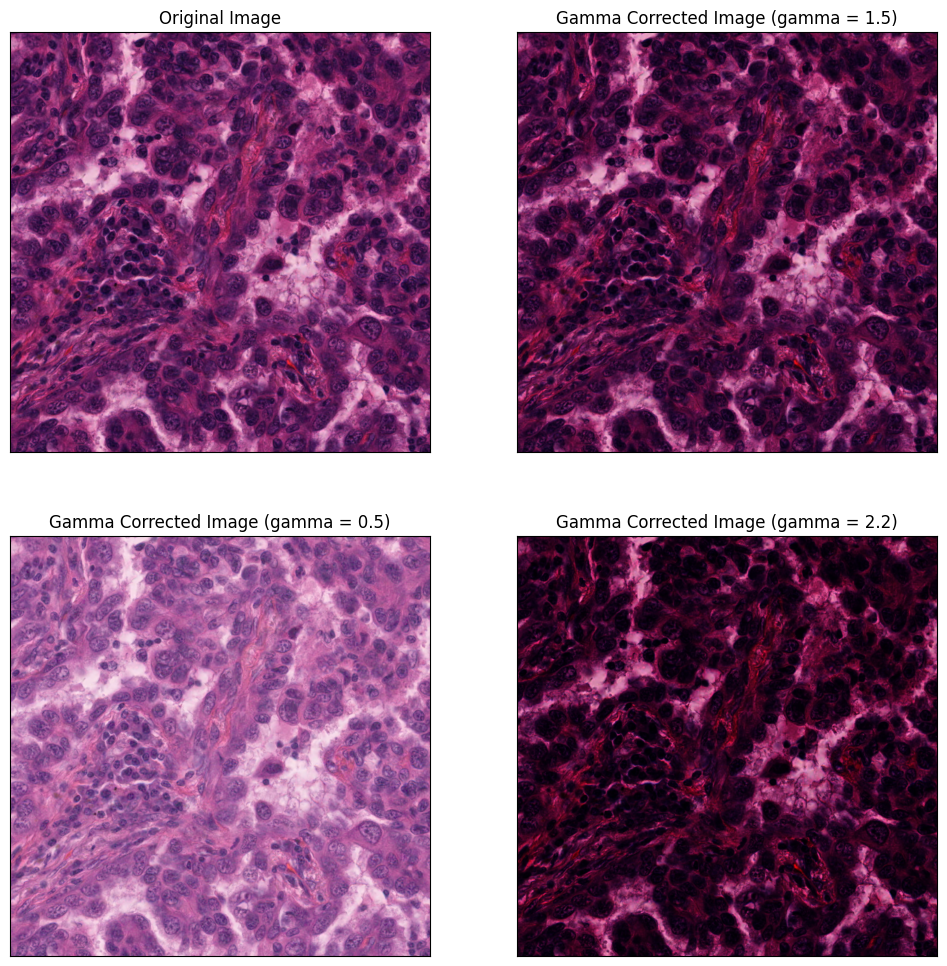

In [16]:
# Adjust the gamma value
gamma1 = 1.5
img_corrected1 = cv.pow(img / float(np.max(img)), gamma1)

gamma2 = 0.5
img_corrected2 = cv.pow(img / float(np.max(img)), gamma2)

gamma3 = 2.2
img_corrected3 = cv.pow(img / float(np.max(img)), gamma3)

# Display the results
plt.figure(figsize=(12, 12))
plt.subplot(221), plt.imshow(img[:, :, ::-1])
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(img_corrected1[:, :, ::-1])
plt.title(f'Gamma Corrected Image (gamma = {gamma1})'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_corrected2[:, :, ::-1])
plt.title(f'Gamma Corrected Image (gamma = {gamma2})'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(img_corrected3[:, :, ::-1])
plt.title(f'Gamma Corrected Image (gamma = {gamma3})'), plt.xticks([]), plt.yticks([])
plt.show()